## 前言  
* 数据处理主要使用**pandas==1.2.4**  
* 可视化部分主要使用**seaborn**  


### 1、库导入及数据读取

In [120]:
!pip install geopy

In [121]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter

sns.set_style("whitegrid")

#### 问题1：读取数据

In [ ]:
# 补充以下代码，数据路径为“"./data/train.csv"”，使用变量df存储读取的dataframe，输出前5行数据
# 正确性检验:
# 数据规模为:(52992,20)


####################################

df=


####################################

print("Dataset dimension: {}".format(df.shape))
df.head()  ##数据预览


Dataset dimension: (52992, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


### 2、数据预处理

#### 问题2：读取数据信息，使用info（）函数,并将结果打印出来

In [ ]:
# 补充以下代码，将infomation进行打印输出
# 正确性检验
# <class 'pandas.core.frame.DataFrame'>
# Index: 41368 entries, 0 to 45592
# Data columns (total 20 columns):
#  #   Column                       Non-Null Count  Dtype         
# ---  ------                       --------------  -----         
#  0   Delivery_person_Age          41368 non-null  float64       
#  1   Delivery_person_Ratings      41368 non-null  float64      
#                        ....... 


####################################

df_info = 

####################################


print(df_info)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52992 entries, 0 to 52991
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           52992 non-null  object 
 1   Delivery_person_ID           52992 non-null  object 
 2   Delivery_person_Age          52992 non-null  object 
 3   Delivery_person_Ratings      52992 non-null  object 
 4   Restaurant_latitude          52992 non-null  float64
 5   Restaurant_longitude         52992 non-null  float64
 6   Delivery_location_latitude   52992 non-null  float64
 7   Delivery_location_longitude  52992 non-null  float64
 8   Order_Date                   52992 non-null  object 
 9   Time_Orderd                  52992 non-null  object 
 10  Time_Order_picked            52992 non-null  object 
 11  Weatherconditions            52992 non-null  object 
 12  Road_traffic_density         52992 non-null  object 
 13  Vehicle_conditio

#### 问题3：缺失值处理

In [ ]:
# 补充以下代码，将“NaN ”替换为np.nan，并删除缺失值，
# 


####################################
df=


####################################

# 正确性检验
# 处理后的数据量为(48064, 20)，使用shape函数自行核对
print("删除缺失值后的数据量：{}".format(df.shape))

删除缺失值后的数据量：(48064, 20)


#### 问题4：重复值处理

In [ ]:
#补充以下代码，如果具有相同的行，进行重复值处理
####################################  
df=


####################################

# 正确性检验
# 处理后的数据量为(41368, 20)，使用shape函数自行核对
print("删除重复值后的数据量：{}".format(df.shape))

删除缺失值后的数据量：(41368, 20)


#### 2.4、时间数据处理

In [126]:
## 将原时间类型(日-月-年) 修改为 (年-月-日)
df["Order_Date"] = df["Order_Date"].map(lambda x:"-".join(x.split("-")[::-1])) 

In [127]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])   
df["Day_name"] = df["Order_Date"].dt.day_name()  ##获取周末

### 3、送餐基本数据探索性分析

In [128]:
def RemoveBorder():
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['bottom'].set_visible(False)
    plt.gca().spines['left'].set_visible(False)

In [129]:
## 删除无关数据
df.drop(["ID","Delivery_person_ID"],axis=1,inplace=True)
## 对 耗时 列进行去时间标签处理
df["Time_taken(min)"] = df["Time_taken(min)"].map(lambda x:x.split(" ")[1])
df["Time_taken(min)"] = df["Time_taken(min)"].astype(int)
## 数据值类型转换
df["Delivery_person_Age"] = df["Delivery_person_Age"].astype(float)
df["Delivery_person_Ratings"] = df["Delivery_person_Ratings"].astype(float)

#### 问题5：请算出配送人员的平均年龄

In [ ]:
# 补充以下代码，计算配送人员的平均年龄，输出数据为int类型，使用变量average_age存储

####################################
average_age = 


####################################


# 正确性检验
# 正确答案为:29 
print("配送人员的平均年龄为:{}".format(average_age))

配送人员的平均年龄为:29


#### 问题6：请绘制骑手年龄和骑手配送时间之间的折线关系图

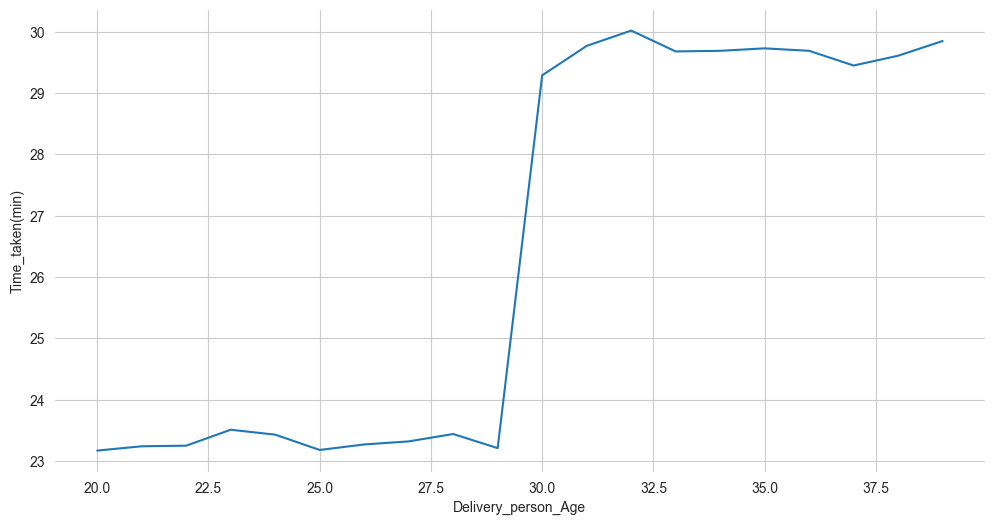

In [ ]:
# 补充以下代码，横轴为平均年龄，纵轴为配送时间

####################################




####################################
RemoveBorder()
plt.show()

#### 问题7：截止目前为止，计算各类配送产品的订单量的柱状图（可以使用counter函数或者其他方法）

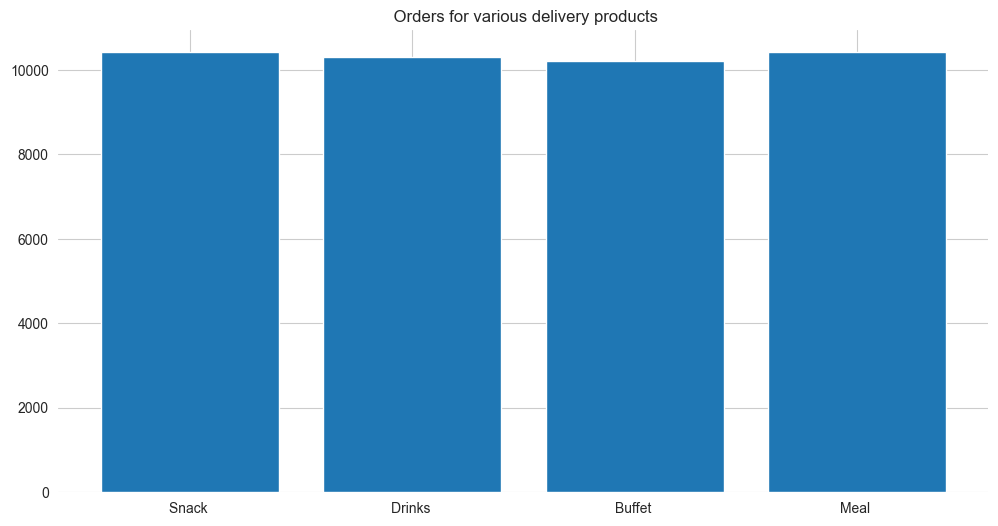

In [ ]:
# 补充以下代码
# 柱状图横轴是各类商品,纵轴是该类商品的订单量

####################################





####################################

RemoveBorder()
plt.title(" Orders for various delivery products")
plt.show()


#### 问题8：请输出配送订单最多的三类产品

In [ ]:
# 补充以下代码，输出为一个字典，输出格式为{'品类1': 数量, '品类2 ': 数量, '品类3 ': 数量}，使用变量result_dict存储
# 正确性检验
# 最多的前三类分别为Meal Snack Drinks
####################################
result_dict=



####################################
print(result_dict)

{'Meal ': 10421, 'Snack ': 10419, 'Drinks ': 10302}


### 4、送餐距离探索性分析

#### 问题9、根据餐馆的经纬度（Restaurant_latitude，Restaurant_longitude），目的地经纬度（Delivery_location_latitude，Delivery_location_longitude）计算送餐距离，计算结果在df中新增一列进行存储，列名为Distance(km)，根据本题数据完成问题10

In [ ]:
from geopy.distance import geodesic as GD

def distance_from_pickup_point(tag1,tag2,tag3,tag4):
    res = []
    
    #########################



    #########################

    return res

df["Distance(km)"] = distance_from_pickup_point("Restaurant_latitude","Restaurant_longitude",\
                                                "Delivery_location_latitude","Delivery_location_longitude")


In [135]:
df[["Distance(km)"]]

,Distance(km)
0,3.02
1,20.14
2,1.55
3,7.77
4,6.20
...,...
46788,1.49
46789,10.98
46790,4.65
46791,6.22


#### 问题10：画出配送距离与配送员评分的关系图，横轴为配送距离，纵轴为配送评分

In [ ]:
fig = plt.figure(figsize=(12,6))
#补充以下代码，可根据自身理解需求选择合适的关系图
#####################################3




#####################################3
plt.show()